# The on–off stochastic moisture model of Martinez-Villalobos and Neelin (2019)

This notebook integrates the single-column stochastic model of column water vapor and precipitation in

> Martinez-Villalobos, C., and J. D. Neelin, 2019: Why do precipitation intensities tend to follow gamma distributions? *J. Atmos. Sci.*, **76**, 3611–3631, https://doi.org/10.1175/JAS-D-18-0343.1

(MN19 below; equation and figure numbers refer to it). The notebook uses the on–off precipitation version of the model with the parameters of MN19 Fig. 2b, which shows that version's accumulation and daily-precipitation distributions. The notebook compares the simulated distributions of event accumulations, wet- and dry-spell durations and daily precipitation with the paper's analytical results.

The notebook needs numpy, matplotlib and numba, and runs in 2 to 4 minutes on an Intel laptop, most of it in a 100-year integration at a time step of 0.6 s.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numba
import numpy as np

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

## 1. Model equations and parameters

Column water vapor $q$ (mm) obeys MN19 eqs. (5)–(7):

$$\frac{dq}{dt} = E + \bar C + D_E\,\eta \qquad \text{(dry regime)},$$

$$\frac{dq}{dt} = E + \bar C - R_0 + D_P\,\eta \qquad \text{(wet regime)}.$$

$E$ is the mean evaporation, $\bar C$ the climatological mean moisture convergence, $R_0$ the precipitation rate, and $\eta$ Gaussian white noise, $\langle \eta(t)\,\eta(t')\rangle = \delta(t - t')$, whose amplitudes $D_E$ and $D_P$ represent fluctuations in moisture convergence. Precipitation starts when $q$ rises above $q_c$ and stops when $q$ falls below $q_{np} = q_c - b$.

Following MN19 section 3a, the integration also

- sets $E + \bar C = 0$ in the wet regime, so that the wet-regime tendency is $-R_0 + D_P\,\eta$;
- puts a rigid lower boundary at $q$ = 1 mm: a time step that would take $q$ below it is discarded, and $q$ keeps its previous value.

The parameters are those of MN19 Fig. 2b. The initial value of $q$ is not from MN19.

In [2]:
# MN19 Fig. 2 caption (on-off precipitation), plus the lower boundary of their section 3a
MN19_FIG2 = dict(
    q_c=65.0,     # mm, precipitation starts when q rises above q_c
    b=0.2,        # mm, and stops when q falls below q_np = q_c - b
    q_min=1.0,    # mm, rigid lower boundary on q
    E=0.1,        # mm/h, mean evaporation
    C=0.2,        # mm/h, climatological mean moisture convergence, C-bar
    R_0=9.0,      # mm/h, precipitation rate while precipitating
    D_E=3.0,      # mm h^-1/2, noise amplitude in the dry regime
    D_P=17.0,     # mm h^-1/2, noise amplitude in the wet regime
    q_init=64.9,  # mm, initial value (not from MN19), between q_np and q_c
)


def theory(p):
    # MN19's continuum predictions, in mm and hours: eq. (10) for accumulations,
    # eq. (B2) for wet spells, appendix B for dry spells (ignoring the lower boundary)
    source = p["E"] + p["C"]
    return dict(
        accum_mean=p["b"],
        accum_cutoff=2 * p["D_P"] ** 2 / p["R_0"],
        wet_mean=p["b"] / p["R_0"],
        wet_cutoff=2 * p["D_P"] ** 2 / p["R_0"] ** 2,
        dry_mean=p["b"] / source,
        dry_cutoff=2 * p["D_E"] ** 2 / source**2,
    )


for name, value in theory(MN19_FIG2).items():
    print(f"{name:>12s}: {value:.4g}")

  accum_mean: 0.2
accum_cutoff: 64.22
    wet_mean: 0.02222
  wet_cutoff: 7.136
    dry_mean: 0.6667
  dry_cutoff: 200


## 2. Time stepping: why the noise term scales with $\sqrt{\Delta t}$

MN19 integrate with the Euler–Maruyama scheme (their section 3b). Over a time step $\Delta t$ the white noise integrates to a Gaussian increment of variance $D^2 \Delta t$, so one step is

$$q_{n+1} = q_n + f\,\Delta t + D\,\sqrt{\Delta t}\,\xi_n, \qquad \xi_n \sim \mathcal{N}(0, 1),$$

with $f = E + \bar C$ and $D = D_E$ in the dry regime, and $f = -R_0$ and $D = D_P$ in the wet regime. After a time $T$ of noise alone the variance of $q$ is $D^2 T$, whatever the time step. Multiplying the noise by $\Delta t$ instead, like the deterministic tendency, gives a variance of $D^2 T\,\Delta t$, which shrinks with the time step and changes with the unit $\Delta t$ is measured in. The cell below checks both on random walks one hour long.

In [3]:
rng = np.random.default_rng(0)
D = MN19_FIG2["D_P"]  # mm h^-1/2
T = 1.0  # h
n_walks = 2000
print(f"Variance of q after {T:g} h of noise alone, D = {D:g} mm h^-1/2, {n_walks} walks;")
print(f"the exact value is D^2 T = {D**2 * T:g} mm^2.\n")
print(f"{'time step':>10s}{'D sqrt(dt) xi':>16s}{'D dt xi':>12s}   (mm^2, dt in hours)")
for dt_seconds in [60.0, 6.0, 0.6]:
    dt = dt_seconds / 3600  # h
    xi = rng.standard_normal((n_walks, round(T / dt)))
    var_sqrt = (D * np.sqrt(dt) * xi).sum(axis=1).var()
    var_lin = (D * dt * xi).sum(axis=1).var()
    print(f"{dt_seconds:>8g} s{var_sqrt:>16.0f}{var_lin:>12.3g}")

Variance of q after 1 h of noise alone, D = 17 mm h^-1/2, 2000 walks;
the exact value is D^2 T = 289 mm^2.

 time step   D sqrt(dt) xi     D dt xi   (mm^2, dt in hours)
      60 s             305        5.09
       6 s             282       0.471


     0.6 s             290      0.0483


## 3. The model as one Python function

`simulate` advances the model one Euler–Maruyama step at a time and records statistics as it goes, so a long integration needs little memory. For each integration `simulate` returns

- the precipitation total of each day;
- the number of rain events in each day, counting an event that spans midnight in both days (MN19 do not state their convention);
- the accumulation of each rain event, $s = R_0 \times$ its duration (eq. 3), and the duration of each rain event (wet spell) and of each dry spell, in time steps;
- the number of time steps spent in each 1-mm bin of $q$;
- the total of each term of the moisture budget.

Units are MN19's: mm for $q$ and hours for time. `run` wraps `simulate`, seeding the random number generator, converting the output to physical units, and dropping the first spell, whose start is the start of the run.

In [4]:
def simulate(n_days, dt, q_c, b, q_min, E, C, R_0, D_E, D_P, q_init, rng, n_save):
    # Integrate the on-off model of MN19 for n_days days with time step dt (hours).
    # rng is a numpy random Generator. The first n_save steps of q and of the
    # precipitation rate are kept for plotting.
    steps_per_day = round(24.0 / dt)
    sqrt_dt = np.sqrt(dt)
    q_np = q_c - b  # precipitation stops once q falls below q_np

    daily_rain = np.zeros(n_days)  # mm
    events_in_day = np.zeros(n_days, dtype=np.int64)
    accumulations = []  # mm, one per completed rain event
    wet_steps = []  # duration of each completed rain event, in steps
    dry_steps = []  # duration of each completed dry spell, in steps
    q_counts = np.zeros(400, dtype=np.int64)  # steps spent in 1-mm bins of q
    q_saved = np.zeros(n_save)
    rain_saved = np.zeros(n_save)
    # Totals of the terms of the moisture budget, in mm:
    # q_end - q_init = source - rain + noise + boundary
    source_total = rain_total = noise_total = boundary_total = 0.0

    q = q_init
    raining = q > q_c
    spell = 0  # steps elapsed in the current rain event or dry spell
    accum = 0.0  # mm, accumulation of the current rain event
    for i in range(n_days * steps_per_day):
        day = i // steps_per_day
        if raining and (spell == 0 or i % steps_per_day == 0):
            events_in_day[day] += 1  # an event starting, or one continuing from the day before

        # One Euler-Maruyama step of eq. (5), or of eqs. (6)-(7) with E + C = 0
        if raining:
            drift = -R_0
            noise = D_P * sqrt_dt * rng.standard_normal()
        else:
            drift = E + C
            noise = D_E * sqrt_dt * rng.standard_normal()
        q_new = q + drift * dt + noise

        # Rigid lower boundary: discard a step that would take q below q_min
        if q_new < q_min:
            boundary_total += q - q_new
            q_new = q

        if raining:
            rain_total += R_0 * dt
            daily_rain[day] += R_0 * dt
            accum += R_0 * dt
        else:
            source_total += (E + C) * dt
        noise_total += noise
        if i < n_save:
            q_saved[i] = q_new
            rain_saved[i] = R_0 if raining else 0.0
        q = q_new
        q_counts[min(max(int(q), 0), q_counts.size - 1)] += 1
        spell += 1

        # Regime for the next step, with hysteresis between q_np and q_c
        if raining and q < q_np:
            accumulations.append(accum)
            wet_steps.append(spell)
            raining = False
            spell = 0
            accum = 0.0
        elif not raining and q > q_c:
            dry_steps.append(spell)
            raining = True
            spell = 0

    budget = np.array([q - q_init, source_total, rain_total, noise_total, boundary_total])
    return (daily_rain, events_in_day, accumulations, wet_steps, dry_steps, q_counts,
            q_saved, rain_saved, budget)

In [5]:
BUDGET_TERMS = ["change in q", "E + C source", "precipitation", "noise", "lower boundary"]


def run(model, params, n_days, dt_seconds, seed, n_save=0):
    # Integrate with `model` (simulate, or its compiled copy) and return a dict
    # of the output in mm and hours.
    dt = dt_seconds / 3600  # h
    steps_per_day = round(24 / dt)
    assert abs(steps_per_day * dt - 24) < 1e-9, "the time step must divide a day"
    t0 = time.perf_counter()
    (daily, events_in_day, accum, wet_steps, dry_steps, q_counts, q_saved, rain_saved,
     budget) = model(n_days, dt, rng=np.random.default_rng(seed), n_save=n_save, **params)
    wall_s = time.perf_counter() - t0
    accum, wet_steps, dry_steps = np.array(accum), np.array(wet_steps), np.array(dry_steps)
    if params["q_init"] > params["q_c"]:  # drop the first spell, whose start is the start of the run
        accum, wet_steps = accum[1:], wet_steps[1:]
    else:
        dry_steps = dry_steps[1:]
    return dict(
        params=params, dt_seconds=dt_seconds, n_days=n_days, seed=seed, wall_s=wall_s,
        dt_h=dt, rain_step=params["R_0"] * dt,  # one step's duration (h) and precipitation (mm)
        daily=daily, events_in_day=events_in_day, accum=accum,
        wet_h=wet_steps * dt, dry_h=dry_steps * dt,
        q_counts=q_counts, q_saved=q_saved, rain_saved=rain_saved,
        budget_per_day=dict(zip(BUDGET_TERMS, budget / n_days)),
    )

## 4. Two days of the model in pure Python

The upper panel shows $q$, and the lower panel the precipitation rate, which is either 0 or $R_0$ = 9 mm h$^{-1}$. Each daily total is the sum of the accumulations of the events in that day, as in the schematic of MN19 Fig. 1. The seed was chosen so that both days have rain.

pure Python: 0.38 s per simulated day at dt = 0.6 s


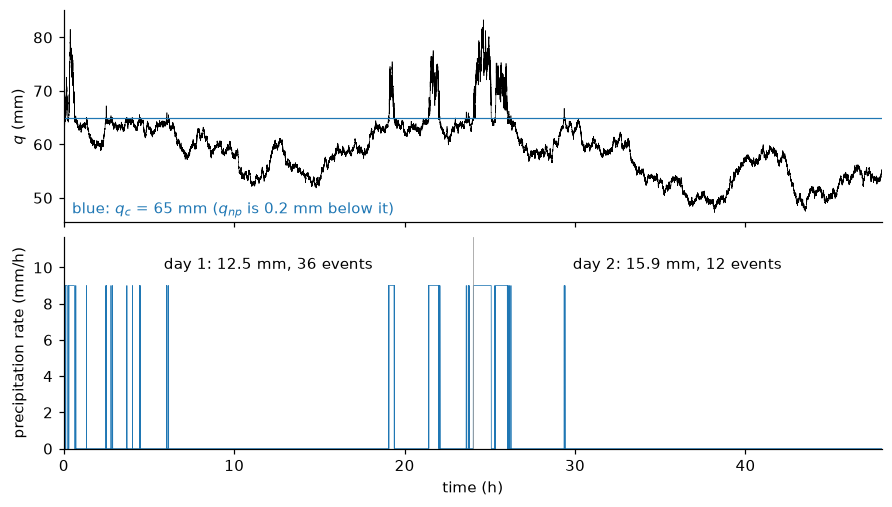

In [6]:
DEMO_DAYS = 2
DEMO_DT = 0.6  # s
DEMO_SEED = 21
n_save = round(DEMO_DAYS * 86400 / DEMO_DT)
demo = run(simulate, MN19_FIG2, n_days=DEMO_DAYS, dt_seconds=DEMO_DT, seed=DEMO_SEED,
           n_save=n_save)
print(f"pure Python: {demo['wall_s'] / DEMO_DAYS:.2f} s per simulated day at dt = {DEMO_DT} s")

p = MN19_FIG2
t = np.arange(1, n_save + 1) * DEMO_DT / 3600  # h, at the end of each step
fig, (ax_q, ax_r) = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True, constrained_layout=True)
ax_q.plot(t, demo["q_saved"], color="k", lw=0.4)
ax_q.axhline(p["q_c"], color="tab:blue", lw=0.8)
ax_q.text(0.01, 0.04, f"blue: $q_c$ = {p['q_c']:g} mm ($q_{{np}}$ is {p['b']:g} mm below it)",
          color="tab:blue", transform=ax_q.transAxes)
ax_q.set_ylabel("$q$ (mm)")
ax_r.plot(t, demo["rain_saved"], color="tab:blue", lw=0.5)
for d in range(DEMO_DAYS):
    ax_r.axvline(24 * d, color="0.6", lw=0.5)
    ax_r.text(24 * d + 12, 1.08 * p["R_0"], f"day {d + 1}: {demo['daily'][d]:.1f} mm, "
              f"{demo['events_in_day'][d]} events", ha="center", va="bottom")
ax_r.set(xlabel="time (h)", ylabel="precipitation rate (mm/h)", ylim=(0, 1.3 * p["R_0"]),
         xlim=(0, 24 * DEMO_DAYS))
plt.show()

## 5. The same function compiled with numba

`numba.njit(simulate)` compiles the unchanged function to machine code. Given the same seed, the compiled copy draws the same random numbers and returns the same output, bit for bit. The cell below checks this on the two-day run and compares the speeds.

In [7]:
simulate_fast = numba.njit(simulate)

fast = run(simulate_fast, MN19_FIG2, n_days=DEMO_DAYS, dt_seconds=DEMO_DT, seed=DEMO_SEED,
           n_save=n_save)
for key in ["daily", "events_in_day", "accum", "wet_h", "dry_h", "q_counts", "q_saved",
            "rain_saved"]:
    assert np.array_equal(demo[key], fast[key]), key
assert demo["budget_per_day"] == fast["budget_per_day"]
print("The compiled and pure-Python outputs are identical.")

# Time a second call, since the first one includes the compilation
fast = run(simulate_fast, MN19_FIG2, n_days=DEMO_DAYS, dt_seconds=DEMO_DT, seed=DEMO_SEED,
           n_save=n_save)
speedup = demo["wall_s"] / fast["wall_s"]
print(f"numba: {fast['wall_s'] / DEMO_DAYS:.4f} s per simulated day, {speedup:.0f} times faster.")
print(f"In pure Python, the 100-year integration below would take about "
      f"{36500 * demo['wall_s'] / DEMO_DAYS / 3600:.1f} hours.")

The compiled and pure-Python outputs are identical.
numba: 0.0067 s per simulated day, 57 times faster.
In pure Python, the 100-year integration below would take about 3.9 hours.


## 6. A 100-year integration at a time step of 0.6 s

MN19 Fig. 2b comes from 100 years at a time step of 0.6 s, which they chose to resolve the smallest accumulations (their section 3b). The moisture budget lists each term of $q_{end} - q_{init}$, as an average per day. A step discarded at the lower boundary leaves more water in the column than the step would have, so the boundary term is a source of water.

In [8]:
N_DAYS = 365 * 100


def overview(res):
    p = res["params"]
    wet_day = res["daily"] > 0
    print(f"dt = {res['dt_seconds']:g} s, {res['n_days'] // 365} years, seed {res['seed']}, "
          f"wall time {res['wall_s']:.0f} s")
    print(f"mean precipitation          {res['daily'].mean():.2f} mm/day")
    print(f"fraction of time raining    {res['daily'].mean() / (24 * p['R_0']):.4f}")
    print(f"fraction of days wet        {wet_day.mean():.3f}")
    print(f"rain events                 {res['accum'].size}")
    print(f"rain events per wet day     {res['events_in_day'][wet_day].mean():.1f}")
    print(f"highest q                   {np.flatnonzero(res['q_counts']).max() + 1} mm "
          f"(upper edge of the highest 1-mm bin reached)")
    print("moisture budget, mm/day:")
    bud = res["budget_per_day"]
    for term, value in bud.items():
        print(f"    {term:24s}{value:12.4g}")
    residual = bud["change in q"] - (bud["E + C source"] - bud["precipitation"]
                                     + bud["noise"] + bud["lower boundary"])
    print(f"    {'residual':24s}{residual:12.2g}")


main = run(simulate_fast, MN19_FIG2, n_days=N_DAYS, dt_seconds=0.6, seed=2)
overview(main)

dt = 0.6 s, 100 years, seed 2, wall time 105 s
mean precipitation          7.01 mm/day
fraction of time raining    0.0325
fraction of days wet        0.588
rain events                 726784
rain events per wet day     33.9
highest q                   235 mm (upper edge of the highest 1-mm bin reached)
moisture budget, mm/day:
    change in q               -0.0002501
    E + C source                   6.966
    precipitation                   7.01
    noise                       -0.07511
    lower boundary                0.1189
    residual                    -2.5e-07


### Distribution of column water vapor

Below $q_{np}$ only the dry-regime walk is present, drifting up toward $q_c$ at $E + \bar C$; above $q_c$ only the wet-regime walk, drifting down at $R_0$. In each region the stationary Fokker–Planck equation with zero net flux gives an exponential PDF, decaying downward from $q_{np}$ with e-folding length $D_E^2/[2(E + \bar C)]$ and upward from $q_c$ with e-folding length $D_P^2/(2R_0)$. These two lengths are derived here and are not in MN19. The next cell fits both slopes to the simulated PDF.

e-folding length below q_np, fitted over 15-59.8 mm: 15.4 mm; D_E^2 / [2(E + C)] = 15.0 mm
e-folding length above q_c, fitted over 70-145 mm: 16.2 mm; D_P^2 / (2 R_0) = 16.1 mm


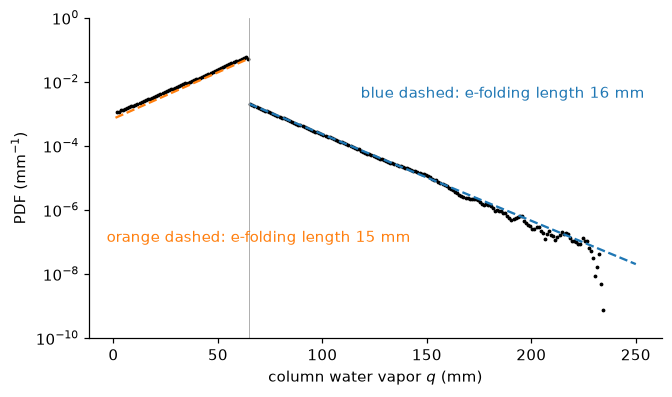

In [9]:
def efolding_length(centers, pdf, lo, hi):
    # Length L of the best-fit exp(+-q / L) over lo < q < hi
    m = (centers > lo) & (centers < hi) & (pdf > 0)
    slope = np.polyfit(centers[m], np.log(pdf[m]), 1)[0]
    return abs(1 / slope)


def cwv_pdf(res):
    counts = res["q_counts"]
    return np.arange(counts.size) + 0.5, counts / counts.sum()  # per mm (1-mm bins)


centers, pdf = cwv_pdf(main)
p = MN19_FIG2
q_np = p["q_c"] - p["b"]
L_dry = p["D_E"] ** 2 / (2 * (p["E"] + p["C"]))
L_wet = p["D_P"] ** 2 / (2 * p["R_0"])
FIT_BELOW = (15.0, q_np - 5)
FIT_ABOVE = (p["q_c"] + 5, p["q_c"] + 80)
print(f"e-folding length below q_np, fitted over {FIT_BELOW[0]:g}-{FIT_BELOW[1]:g} mm: "
      f"{efolding_length(centers, pdf, *FIT_BELOW):.1f} mm; D_E^2 / [2(E + C)] = {L_dry:.1f} mm")
print(f"e-folding length above q_c, fitted over {FIT_ABOVE[0]:g}-{FIT_ABOVE[1]:g} mm: "
      f"{efolding_length(centers, pdf, *FIT_ABOVE):.1f} mm; D_P^2 / (2 R_0) = {L_wet:.1f} mm")

fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
ax.semilogy(centers[pdf > 0], pdf[pdf > 0], ".", color="k", ms=3)
i_np, i_c = int(q_np), int(p["q_c"])
q_lo = np.linspace(p["q_min"], q_np, 50)
q_hi = np.linspace(p["q_c"], 250, 50)
ax.semilogy(q_lo, pdf[i_np] * np.exp((q_lo - q_np) / L_dry), "--", color="tab:orange")
ax.semilogy(q_hi, pdf[i_c] * np.exp(-(q_hi - p["q_c"]) / L_wet), "--", color="tab:blue")
ax.text(0.03, 0.3, f"orange dashed: e-folding length {L_dry:.0f} mm", color="tab:orange",
        transform=ax.transAxes)
ax.text(0.97, 0.75, f"blue dashed: e-folding length {L_wet:.0f} mm", color="tab:blue",
        transform=ax.transAxes, ha="right")
ax.axvline(p["q_c"], color="0.6", lw=0.5)
ax.set(xlabel="column water vapor $q$ (mm)", ylabel="PDF (mm$^{-1}$)", ylim=(1e-10, 1))
plt.show()

## 7. Accumulations and spell durations

In the continuum limit, a rain event is a first passage of the wet-regime walk from $q_c$ down to $q_{np}$, and a dry spell a first passage of the dry-regime walk from $q_{np}$ up to $q_c$. The accumulations and the durations of both kinds of spell then follow inverse Gaussian distributions, MN19 eqs. (9) and (B1):

$$p_x = \frac{\bar x}{\sqrt{\pi x_L}}\, e^{2\bar x / x_L} \exp\!\left(-\frac{\bar x^2}{x_L\, x}\right) \exp\!\left(-\frac{x}{x_L}\right) x^{-3/2},$$

a power law with exponent 3/2 and an exponential cutoff at $x_L$. The mean is $\bar x$, and the cutoff is $x_L = 2\sigma_x^2 / \bar x$ for variance $\sigma_x^2$. For accumulations $\bar s = b$ and $s_L = 2D_P^2/R_0$ (eq. 10). For wet-spell durations $\bar t = b/R_0$ and $t_L = 2D_P^2/R_0^2$ (eq. B2). For dry-spell durations $\bar t_D = b/(E + \bar C)$ and $t_L^D = 2D_E^2/(E + \bar C)^2$ (appendix B), ignoring the lower boundary.

**Overshoot at the thresholds.** In discrete time $q$ crosses each threshold by a finite amount: the dry-regime walk enters the wet regime somewhat above $q_c$, and the wet-regime walk leaves it somewhat below $q_{np}$. So each rain event, and each dry spell, covers more than the distance $b$ between the thresholds. For a Gaussian random walk, the mean overshoot past a distant level is $\kappa = -\zeta(1/2)/\sqrt{2\pi} \approx 0.583$ times the standard deviation of one step (Chang, J. T., and Y. Peres, 1997: Ladder heights, Gaussian random walks and the Riemann zeta function. *Ann. Probab.*, **25**, 787–802). Because the noise has zero mean, the mean accumulation equals the mean drop in $q$ over an event, so

$$\bar s \approx b + \kappa\,(D_P + D_E)\sqrt{\Delta t},$$

and the mean wet- and dry-spell durations are this distance divided by $R_0$ and by $E + \bar C$ (ignoring, for dry spells, the water added at the lower boundary). The cutoff of a first passage over a fixed distance does not depend on that distance, only on the drift and the noise amplitude, so the overshoot should leave the cutoffs close to MN19's values. This correction is not in MN19.

The table below estimates each cutoff from the simulated mean and variance, $x_L = 2\sigma_x^2/\bar x$; the $\pm$ values are standard errors, of the mean for means and from resampling the events for cutoffs. The same table fits the accumulations with MN19's appendix A regression, $\log p = c_1 + c_2 \log x + c_3 x$ over bins containing at least 10 values, which gives $\tau = -c_2$ and $x_L = -1/c_3$. MN19 do not specify their bins; this notebook spaces them logarithmically, 10 per decade. In the figure below, the solid lines are eqs. (9) and (B1) with MN19's means, and the dashed lines the same equations with the overshoot-corrected means.

In [10]:
KAPPA = 1.4603545088 / np.sqrt(2 * np.pi)  # -zeta(1/2) / sqrt(2 pi)


def log_binned_pdf(x, quantum, bins_per_decade=10, min_count=10):
    # PDF per unit x on logarithmically spaced bins with at least min_count values.
    # x comes in whole multiples of `quantum` (one time step, or one step's
    # precipitation), so the bin edges sit halfway between multiples and every bin
    # covers whole quanta. Dividing by the bin width in x, not in log x, makes the
    # slope on log-log axes equal to the power-law exponent.
    k = np.rint(x / quantum)
    top = np.log10(k.max()) + 1 / bins_per_decade
    k_edges = np.r_[0.5, np.unique(np.floor(10 ** np.arange(0, top, 1 / bins_per_decade))) + 0.5]
    counts, _ = np.histogram(k, k_edges)
    keep = counts >= min_count
    centers = quantum * np.sqrt((k_edges[:-1] + 0.5) * (k_edges[1:] - 0.5))
    pdf = counts / (x.size * quantum * np.diff(k_edges))
    return centers[keep], pdf[keep]


def first_passage_pdf(x, mean, cutoff):
    # MN19 eqs. (9) and (B1)
    return (mean / np.sqrt(np.pi * cutoff) * np.exp(2 * mean / cutoff)
            * np.exp(-mean**2 / (cutoff * x)) * np.exp(-x / cutoff) * x**-1.5)


def cutoff_from_moments(x):
    # x_L = 2 var / mean, as in MN19 eq. (10)
    return 2 * x.var() / x.mean()


def fit_appendix_a(x, quantum, bins_per_decade=10, min_count=10):
    # MN19 appendix A: regress log p on log x and x; returns (tau, x_L)
    centers, pdf = log_binned_pdf(x, quantum, bins_per_decade, min_count)
    design = np.column_stack([np.ones(centers.size), np.log(centers), centers])
    c, *_ = np.linalg.lstsq(design, np.log(pdf), rcond=None)
    return -c[1], -1 / c[2]


def bootstrap_se(x, stat, n_boot=100, seed=0):
    # Standard error of stat(x), from resampling the events, which are independent
    # first passages
    rng = np.random.default_rng(seed)
    return np.std([stat(x[rng.integers(0, x.size, x.size)]) for _ in range(n_boot)])


def with_overshoot(res):
    # Mean accumulation and mean spell durations: MN19's continuum values with the
    # distance b lengthened by the mean overshoot past q_c and q_np (the dry-spell
    # value ignores the water added at the lower boundary)
    p = res["params"]
    distance = p["b"] + KAPPA * (p["D_P"] + p["D_E"]) * np.sqrt(res["dt_h"])  # mm
    return dict(accum_mean=distance, wet_mean=distance / p["R_0"],
                dry_mean=distance / (p["E"] + p["C"]))


def spell_table(res):
    # Means and cutoffs of accumulations and spell durations against MN19
    # The +- values are standard errors: of the mean for means, and from
    # bootstrap_se for cutoffs
    th, ov = theory(res["params"]), with_overshoot(res)
    s, wet_min, dry_min = res["accum"], 60 * res["wet_h"], 60 * res["dry_h"]
    rows = []
    for name, x, mean_key, unit in [("accumulation (mm)", s, "accum_mean", 1),
                                    ("wet spell (min)", wet_min, "wet_mean", 60),
                                    ("dry spell (min)", dry_min, "dry_mean", 60)]:
        rows.append((f"mean {name}", x.mean(), x.std() / np.sqrt(x.size), unit * th[mean_key],
                     unit * ov[mean_key]))
    for name, x, cutoff_key in [("accumulation cutoff s_L (mm)", s, "accum_cutoff"),
                                ("wet-spell cutoff t_L (h)", res["wet_h"], "wet_cutoff"),
                                ("dry-spell cutoff t_L^D (h)", res["dry_h"], "dry_cutoff")]:
        rows.append((name, cutoff_from_moments(x), bootstrap_se(x, cutoff_from_moments),
                     th[cutoff_key]))
    tau, s_L = fit_appendix_a(s, res["rain_step"])
    rows += [("appendix A fit to accumulations: tau", tau, None, 1.5),
             ("appendix A fit to accumulations: s_L (mm)", s_L, None, th["accum_cutoff"])]
    print(f"dt = {res['dt_seconds']:g} s")
    print(f"{'':42s}{'simulated':>17s}{'MN19':>8s}{'MN19 + overshoot':>18s}")
    for name, sim, se, thy, *corr in rows:
        sim = f"{sim:.3g} +- {se:.2g}" if se is not None else f"{sim:.3g}"
        corr = f"{corr[0]:>18.3g}" if corr else ""
        print(f"{name:42s}{sim:>17s}{thy:>8.3g}{corr}")

kappa = -zeta(1/2) / sqrt(2 pi) = 0.583



dt = 0.6 s
                                                  simulated    MN19  MN19 + overshoot
mean accumulation (mm)                      0.352 +- 0.0039     0.2              0.35
mean wet spell (min)                          2.35 +- 0.026    1.33              2.34
mean dry spell (min)                             70 +- 0.73      40              70.1
accumulation cutoff s_L (mm)                    63.9 +- 2.1    64.2
wet-spell cutoff t_L (h)                        7.1 +- 0.24    7.14
dry-spell cutoff t_L^D (h)                       182 +- 5.5     200
appendix A fit to accumulations: tau                   1.46     1.5
appendix A fit to accumulations: s_L (mm)              59.6    64.2

appendix A fit to an exact sample of eq. (9): tau = 1.44, s_L = 53 mm


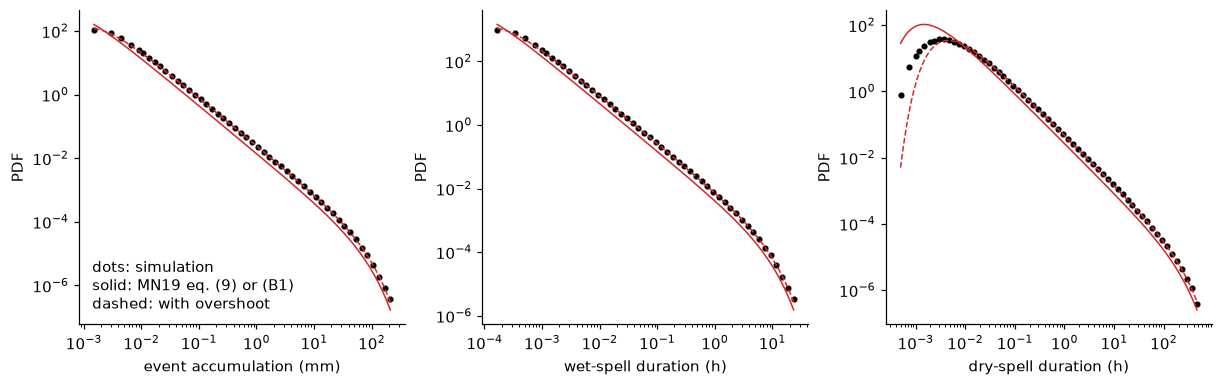

In [11]:
print(f"kappa = -zeta(1/2) / sqrt(2 pi) = {KAPPA:.3f}\n")
spell_table(main)

# Control on the appendix A fit: an exact sample of eq. (9), using numpy's inverse
# Gaussian (Wald) distribution with shape 2 s-bar^2 / s_L (MN19 eq. C1), with the
# simulation's mean, MN19's cutoff, and the same rounding to whole steps
mean, s_L = with_overshoot(main)["accum_mean"], theory(MN19_FIG2)["accum_cutoff"]
exact = np.random.default_rng(0).wald(mean, 2 * mean**2 / s_L, main["accum"].size)
exact = np.maximum(np.rint(exact / main["rain_step"]), 1) * main["rain_step"]
tau, x_L = fit_appendix_a(exact, main["rain_step"])
print(f"\nappendix A fit to an exact sample of eq. (9): tau = {tau:.2f}, s_L = {x_L:.0f} mm")

th, ov = theory(MN19_FIG2), with_overshoot(main)
panels = [("accum", "rain_step", "event accumulation (mm)", "accum_mean", "accum_cutoff"),
          ("wet_h", "dt_h", "wet-spell duration (h)", "wet_mean", "wet_cutoff"),
          ("dry_h", "dt_h", "dry-spell duration (h)", "dry_mean", "dry_cutoff")]
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4), constrained_layout=True)
for ax, (key, quantum, label, mean_key, cutoff_key) in zip(axs, panels):
    x, pdf = log_binned_pdf(main[key], main[quantum])
    ax.loglog(x, pdf, "o", ms=3, color="k")
    xx = np.logspace(np.log10(x[0]), np.log10(x[-1]), 300)
    ax.loglog(xx, first_passage_pdf(xx, th[mean_key], th[cutoff_key]), color="tab:red", lw=1)
    ax.loglog(xx, first_passage_pdf(xx, ov[mean_key], th[cutoff_key]), "--", color="tab:red",
              lw=1)
    ax.set(xlabel=label, ylabel="PDF")
axs[0].text(0.04, 0.05, "dots: simulation\nsolid: MN19 eq. (9) or (B1)\ndashed: with overshoot",
            transform=axs[0].transAxes)
plt.show()

The simulated cutoffs $s_L$ and $t_L$ lie within one standard error of MN19's values, and the simulated means within one standard error of the overshoot-corrected ones. MN19's means are smaller because they leave out the overshoot. The appendix A fit gives a power-law exponent of 1.46 against the exact 3/2, and the same fit gives 1.44 on an exact sample of eq. (9) with the same mean, cutoff and rounding to whole steps. Eq. (A1) has no counterpart of the factor $\exp(-\bar s^2/(s_L s))$, which lowers eq. (9) at the smallest accumulations, so a fitted exponent below 3/2 is a property of the regression; the simulated accumulations are consistent with eq. (9).

The dry-spell cutoff, 182 h, falls short of $2D_E^2/(E + \bar C)^2$ = 200 h by more than three standard errors; that continuum value ignores the lower boundary. The cell below integrates the model with and without the boundary, at a time step of 1 min to keep it fast; section 9 compares the two time steps.

In [12]:
one_min = run(simulate_fast, MN19_FIG2, n_days=N_DAYS, dt_seconds=60.0, seed=3)
no_boundary = run(simulate_fast, dict(MN19_FIG2, q_min=-1e9), n_days=N_DAYS, dt_seconds=60.0,
                  seed=3)
print(f"dry-spell cutoff 2 D_E^2 / (E + C)^2: {theory(MN19_FIG2)['dry_cutoff']:.0f} h")
for name, res in [("with the lower boundary", one_min), ("without it", no_boundary)]:
    print(f"{name:>24s}: cutoff {cutoff_from_moments(res['dry_h']):.0f} h, "
          f"longest dry spell {res['dry_h'].max():.0f} h")

dry-spell cutoff 2 D_E^2 / (E + C)^2: 200 h
 with the lower boundary: cutoff 181 h, longest dry spell 804 h
              without it: cutoff 205 h, longest dry spell 1123 h


Without the boundary the dry-spell cutoff is 205 h, against the continuum 200 h; with it, 181 h. The boundary removes the longest dry spells, those in which $q$ falls far below $q_c$: the longest is 804 h with the boundary and 1123 h without.

## 8. Daily precipitation

MN19 fit wet-day precipitation totals with their eq. (2), $p_P = A P^{-\tau_P} \exp(-P/P_L)$ with $A = P_L^{\tau_P - 1}/\Gamma(1 - \tau_P)$: a gamma distribution with power-law exponent $\tau_P$ and cutoff $P_L$. MN19 estimate $\tau_P$ and $P_L$ in two ways. The appendix A regression gives the values printed in their Fig. 2b. The method of moments, eq. (D6), solves $\bar P = (1 - \hat\tau_P)\hat P_L$ and $\sigma_P^2 = (1 - \hat\tau_P) \hat P_L^2$. Their section 5a then approximates the method-of-moments values from the accumulation statistics and from the mean $\bar w$ and variance $\sigma_w^2$ of the number of events per wet day, eqs. (17) and (18):

$$\hat P_L = \frac{\sigma_w^2}{\bar w}\,\bar s + \frac{s_L}{2}, \qquad \hat\tau_P = 1 - \frac{\bar w}{\sigma_w^2/\bar w + s_L/(2\bar s)}.$$

The table below compares all three, with eqs. (17) and (18) evaluated from the simulated $\bar s$, $s_L$, $\bar w$ and $\sigma_w^2$.

In [13]:
MN19_FIG2B_DAILY_FIT = dict(tau_P=0.50, P_L=29.7)  # appendix A regression, MN19 Fig. 2b


def gamma_pdf(x, tau, x_L):
    # MN19 eq. (2)
    return x_L ** (tau - 1) / math.gamma(1 - tau) * x**-tau * np.exp(-x / x_L)


def fit_moments(x):
    # MN19 eq. (D6); returns (tau, x_L)
    return 1 - x.mean() ** 2 / x.var(), x.var() / x.mean()


def daily_table(res):
    # tau_P and P_L of wet-day totals by three methods; returns the totals and event counts
    wet_day = res["daily"] > 0
    assert np.array_equal(wet_day, res["events_in_day"] > 0)
    P, w = res["daily"][wet_day], res["events_in_day"][wet_day]
    s_mean, s_L = res["accum"].mean(), cutoff_from_moments(res["accum"])
    w_mean, w_var = w.mean(), w.var()
    rows = [
        ("appendix A regression", *fit_appendix_a(P, res["rain_step"])),
        ("MN19 Fig. 2b (appendix A regression)", MN19_FIG2B_DAILY_FIT["tau_P"],
         MN19_FIG2B_DAILY_FIT["P_L"]),
        ("method of moments, eq. (D6)", *fit_moments(P)),
        ("eqs. (17) and (18)", 1 - w_mean / (w_var / w_mean + s_L / (2 * s_mean)),
         w_var / w_mean * s_mean + s_L / 2),
    ]
    print(f"dt = {res['dt_seconds']:g} s: {P.size} wet days; events per wet day: mean "
          f"{w_mean:.2f}, variance {w_var:.1f}; accumulations: mean {s_mean:.3f} mm, "
          f"cutoff {s_L:.1f} mm\n")
    print(f"{'':40s}{'tau_P':>8s}{'P_L (mm)':>10s}")
    for name, tau, P_L in rows:
        print(f"{name:40s}{tau:>8.2f}{P_L:>10.1f}")
    return P, w

dt = 0.6 s: 21469 wet days; events per wet day: mean 33.91, variance 606.2; accumulations: mean 0.352 mm, cutoff 63.9 mm

                                           tau_P  P_L (mm)
appendix A regression                       0.50      27.7
MN19 Fig. 2b (appendix A regression)        0.50      29.7
method of moments, eq. (D6)                 0.60      30.0
eqs. (17) and (18)                          0.69      38.3


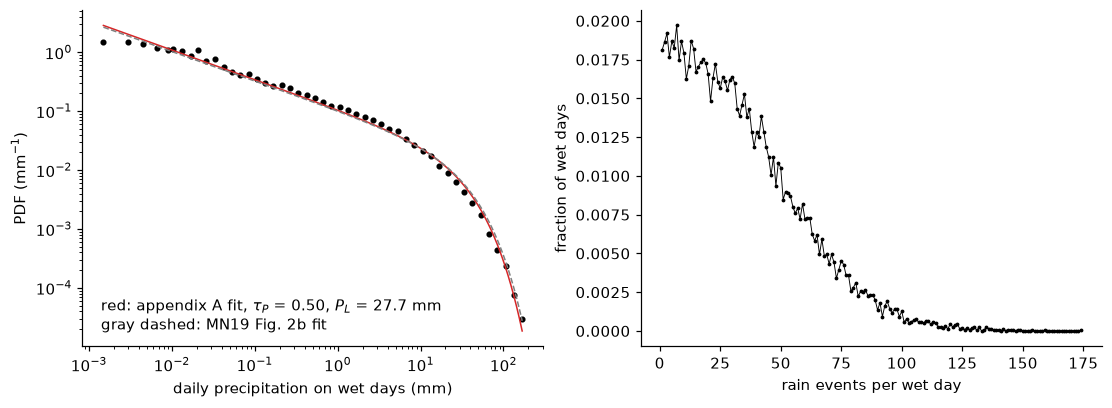

In [14]:
P_main, w_main = daily_table(main)

fig, (ax_p, ax_w) = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
x, pdf = log_binned_pdf(P_main, main["rain_step"])
ax_p.loglog(x, pdf, "o", ms=3, color="k")
xx = np.logspace(np.log10(x[0]), np.log10(x[-1]), 300)
tau, P_L = fit_appendix_a(P_main, main["rain_step"])
ax_p.loglog(xx, gamma_pdf(xx, tau, P_L), color="tab:red", lw=1)
ax_p.loglog(xx, gamma_pdf(xx, MN19_FIG2B_DAILY_FIT["tau_P"], MN19_FIG2B_DAILY_FIT["P_L"]),
            "--", color="0.5", lw=1)
ax_p.text(0.04, 0.05, f"red: appendix A fit, $\\tau_P$ = {tau:.2f}, $P_L$ = {P_L:.1f} mm\n"
          f"gray dashed: MN19 Fig. 2b fit", transform=ax_p.transAxes)
ax_p.set(xlabel="daily precipitation on wet days (mm)", ylabel="PDF (mm$^{-1}$)")
n = np.arange(1, w_main.max() + 1)
ax_w.plot(n, [(w_main == k).mean() for k in n], ".-", ms=3, color="k", lw=0.6)
ax_w.set(xlabel="rain events per wet day", ylabel="fraction of wet days")
plt.show()

The appendix A regression gives $\tau_P$ = 0.50, as in MN19 Fig. 2b, and $P_L$ = 27.7 mm against their 29.7 mm. The method of moments gives $\hat\tau_P$ = 0.60 and $\hat P_L$ = 30.0 mm; MN19 note that the two estimators give different values that are proportional to each other (their appendix A and Fig. S1). Eqs. (17) and (18) give larger values still, $\hat\tau_P$ = 0.69 and $\hat P_L$ = 38.3 mm. MN19 Fig. 4a, which plots $\hat P_L$ against $s_L$ for a set of 500-year integrations, shows the same: their analytical approximation lies above their integrations, by more at larger $s_L$. MN19 attribute the difference to the derivation's assumption that a day is much longer than the wet-spell cutoff $t_L$ (their section 5b4), which is 7.1 h here.

## 9. Sensitivity to the time step

MN19 use a time step of 0.6 s for Fig. 2 and of 1 min for the 500-year integrations of their section 5b. The cells below compare the 100-year integration at 0.6 s with the one at 1 min from section 7.

In [15]:
overview(one_min)
print()
spell_table(one_min)
print()
P_1min, w_1min = daily_table(one_min)

dt = 60 s, 100 years, seed 3, wall time 1 s
mean precipitation          7.07 mm/day
fraction of time raining    0.0327
fraction of days wet        0.561
rain events                 134000
rain events per wet day     6.6
highest q                   217 mm (upper edge of the highest 1-mm bin reached)
moisture budget, mm/day:
    change in q                -0.000194
    E + C source                   6.964
    precipitation                   7.07
    noise                      -0.004979
    lower boundary                0.1104
    residual                    -4.6e-09



dt = 60 s
                                                  simulated    MN19  MN19 + overshoot
mean accumulation (mm)                        1.93 +- 0.021     0.2               1.7
mean wet spell (min)                           12.8 +- 0.14    1.33              11.4
mean dry spell (min)                             379 +- 3.9      40               341
accumulation cutoff s_L (mm)                    63.7 +- 2.7    64.2
wet-spell cutoff t_L (h)                       7.08 +- 0.29    7.14
dry-spell cutoff t_L^D (h)                       181 +- 4.5     200
appendix A fit to accumulations: tau                   1.56     1.5
appendix A fit to accumulations: s_L (mm)                76    64.2

dt = 60 s: 20460 wet days; events per wet day: mean 6.60, variance 21.2; accumulations: mean 1.926 mm, cutoff 63.7 mm

                                           tau_P  P_L (mm)
appendix A regression                       0.61      30.6
MN19 Fig. 2b (appendix A regression)        0.50      29.7
method of

                                     0.6 s      60 s   ratio
rain events lasting one step         0.158     0.451    2.85
mean accumulation (mm)               0.352      1.93    5.47
accumulation cutoff s_L (mm)          63.9      63.7    1.00
mean wet spell (min)                  2.35      12.8    5.47
wet-spell cutoff t_L (h)               7.1      7.08    1.00
mean dry spell (min)                    70       379    5.42
dry-spell cutoff t_L^D (h)             182       181    0.99
rain events per wet day               33.9       6.6    0.19
fraction of days wet                 0.588     0.561    0.95
mean precipitation (mm/day)           7.01      7.07    1.01
daily P_L, eq. (D6) (mm)                30      29.5    0.99
daily tau_P, eq. (D6)                0.602     0.573    0.95
daily P_L, appendix A (mm)            27.7      30.6    1.11
daily tau_P, appendix A              0.504      0.61    1.21
daily P_L, eq. (17) (mm)              38.3        38    0.99
first term of eq. (17) (

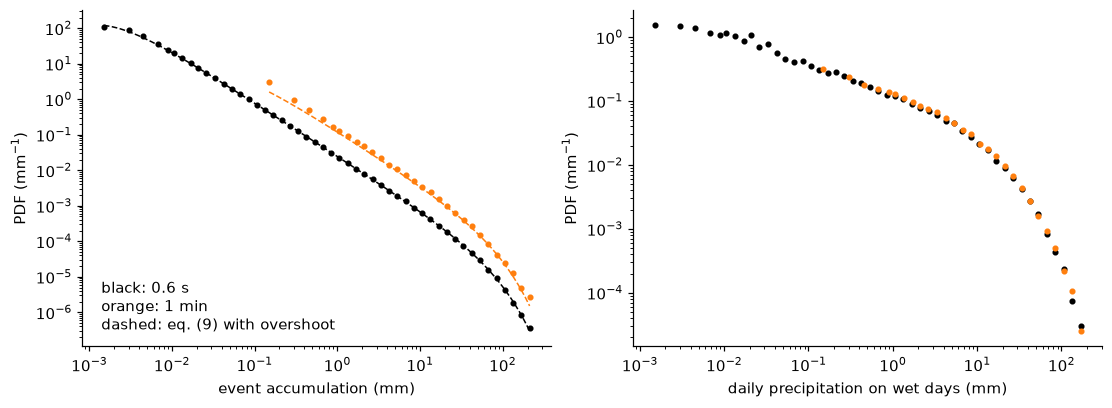

In [16]:
def compare(res_a, res_b, P_a, P_b):
    # Statistics at two time steps, and their ratio
    def stats(res, P):
        tau_m, PL_m = fit_moments(P)
        tau_a, PL_a = fit_appendix_a(P, res["rain_step"])
        w = res["events_in_day"][res["daily"] > 0]
        s_mean, s_L = res["accum"].mean(), cutoff_from_moments(res["accum"])
        return {
            "rain events lasting one step": np.mean(np.isclose(res["wet_h"], res["dt_h"])),
            "mean accumulation (mm)": res["accum"].mean(),
            "accumulation cutoff s_L (mm)": cutoff_from_moments(res["accum"]),
            "mean wet spell (min)": 60 * res["wet_h"].mean(),
            "wet-spell cutoff t_L (h)": cutoff_from_moments(res["wet_h"]),
            "mean dry spell (min)": 60 * res["dry_h"].mean(),
            "dry-spell cutoff t_L^D (h)": cutoff_from_moments(res["dry_h"]),
            "rain events per wet day": res["events_in_day"][res["daily"] > 0].mean(),
            "fraction of days wet": (res["daily"] > 0).mean(),
            "mean precipitation (mm/day)": res["daily"].mean(),
            "daily P_L, eq. (D6) (mm)": PL_m,
            "daily tau_P, eq. (D6)": tau_m,
            "daily P_L, appendix A (mm)": PL_a,
            "daily tau_P, appendix A": tau_a,
            "daily P_L, eq. (17) (mm)": w.var() / w.mean() * s_mean + s_L / 2,
            "first term of eq. (17) (mm)": w.var() / w.mean() * s_mean,
        }
    a, b = stats(res_a, P_a), stats(res_b, P_b)
    label_a, label_b = f"{res_a['dt_seconds']:g} s", f"{res_b['dt_seconds']:g} s"
    print(f"{'':32s}{label_a:>10s}{label_b:>10s}{'ratio':>8s}")
    for key in a:
        print(f"{key:32s}{a[key]:>10.3g}{b[key]:>10.3g}{b[key] / a[key]:>8.2f}")


compare(main, one_min, P_main, P_1min)
p = MN19_FIG2
for res in [main, one_min]:
    sd_wet, sd_dry = p["D_P"] * np.sqrt(res["dt_h"]), p["D_E"] * np.sqrt(res["dt_h"])
    print(f"at {res['dt_seconds']:g} s: one step's noise in the wet regime, D_P sqrt(dt), is "
          f"{sd_wet:.2g} mm, {sd_wet / p['b']:.2g} times b; a rain event starts "
          f"{(p['b'] + KAPPA * sd_dry) / sd_wet:.2g} of those steps above q_np on average")
print(f"mean overshoot, in units of one step's standard deviation: kappa = {KAPPA:.3f} for a "
      f"walk starting far from the level, 1/sqrt(2) = {1 / np.sqrt(2):.3f} for one starting at it")

th = theory(MN19_FIG2)
fig, (ax_s, ax_p) = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for res, P, color in [(main, P_main, "k"), (one_min, P_1min, "tab:orange")]:
    x, pdf = log_binned_pdf(res["accum"], res["rain_step"])
    ax_s.loglog(x, pdf, "o", ms=3, color=color)
    xx = np.logspace(np.log10(x[0]), np.log10(x[-1]), 300)
    ax_s.loglog(xx, first_passage_pdf(xx, with_overshoot(res)["accum_mean"],
                                      th["accum_cutoff"]), "--", color=color, lw=1)
    x, pdf = log_binned_pdf(P, res["rain_step"])
    ax_p.loglog(x, pdf, "o", ms=3, color=color)
ax_s.text(0.04, 0.05, "black: 0.6 s\norange: 1 min\ndashed: eq. (9) with overshoot",
          transform=ax_s.transAxes)
ax_s.set(xlabel="event accumulation (mm)", ylabel="PDF (mm$^{-1}$)")
ax_p.set(xlabel="daily precipitation on wet days (mm)", ylabel="PDF (mm$^{-1}$)")
plt.show()

In [17]:
# The moment estimate of s_L at 1 min, over 20 independent 100-year integrations
N_SEEDS = 20
s_L_1min = np.array([cutoff_from_moments(run(simulate_fast, MN19_FIG2, n_days=N_DAYS,
                                             dt_seconds=60.0, seed=100 + k)["accum"])
                     for k in range(N_SEEDS)])
s_L_th = theory(MN19_FIG2)["accum_cutoff"]
print(f"s_L at 1 min, {N_SEEDS} integrations: mean {s_L_1min.mean():.1f} mm, standard error "
      f"{s_L_1min.std(ddof=1) / np.sqrt(N_SEEDS):.1f} mm, spread between integrations "
      f"(standard deviation) {s_L_1min.std(ddof=1):.1f} mm")
print(f"2 D_P^2 / R_0 = {s_L_th:.1f} mm; mean departure {100 * (s_L_1min.mean() / s_L_th - 1):.1f}%")

s_L at 1 min, 20 integrations: mean 62.3 mm, standard error 0.5 mm, spread between integrations (standard deviation) 2.1 mm
2 D_P^2 / R_0 = 64.2 mm; mean departure -3.0%


At 1 min the means of accumulations and of both kinds of spell are 5.42 to 5.47 times larger than at 0.6 s. Since wet and dry spells both last longer, there are 0.19 times as many rain events per wet day. Among the daily statistics, the mean precipitation, the wet-day fraction and the method-of-moments estimates change by 5% or less, and the appendix A estimates by 11% ($P_L$) and 21% ($\tau_P$).

$\kappa$ is the mean overshoot of a walk that starts many steps away from the level. At 0.6 s a rain event starts on average about one wet-regime step's noise above $q_{np}$, and the overshoot-corrected means match the simulated ones. At 1 min one step's noise in the wet regime is 2.2 mm, 11 times $b$, so a rain event starts only 0.19 of a step's noise above $q_{np}$, and 45% of the 1-min rain events last a single step (16% at 0.6 s). A walk starting at the level overshoots by $1/\sqrt{2} \approx 0.707$ standard deviations on average, more than $\kappa$, so at 1 min the overshoot-corrected means fall short of the simulated ones (the tables above).

The cutoffs from the single integrations at the two time steps agree within their standard errors. Over 20 independent 1-min integrations, though, the moment estimate of $s_L$ averages 62.3 ± 0.5 mm, 3% below $2D_P^2/R_0$ = 64.2 mm, and varies by 2.1 mm (standard deviation) from one integration to the next. Write an event's accumulation as $s = Y + M$, with $Y$ the drop in $q$ over the event ($b$ plus the two overshoots) and $M$ the noise summed over its $N$ steps. Since $s = R_0\,\Delta t\,N$, $\bar s = R_0\,\Delta t\,\overline{N}$, and Wald's second identity, for a sum of independent steps up to a stopping time, gives $\mathrm{var}(M) = D_P^2\,\Delta t\,\overline{N}$. So

$$\frac{2\sigma_s^2}{\bar s} = \frac{2D_P^2}{R_0} + \frac{2\,[\mathrm{var}(Y) + 2\,\mathrm{cov}(M, Y)]}{\bar s}.$$

At 1 min the last term is negative, which requires $Y$ and $M$ to be anticorrelated.

## 10. Experiment: a larger noise amplitude in the wet regime

Eq. (10) gives $s_L \propto D_P^2$, and MN19 eq. (19) and Fig. 4a show that the daily cutoff follows the accumulation cutoff, $\hat P_L \propto s_L$. Multiplying $D_P$ by 1.5 should then multiply $s_L$ by 2.25 and raise the probability of the heaviest days. MN19 make a similar change in the ramp version of the model, multiplying $D_P$ alone by 1.21 (the blue curve of their Fig. 8). Both integrations here use a time step of 1 min, as MN19 do for their parameter sweeps; section 9 compares the daily statistics at the two time steps. The risk ratio plotted below is the one in MN19 Fig. 8: the ratio of the probabilities, on wet days, that daily precipitation exceeds $x$.

dt = 60 s, 100 years, seed 4, wall time 1 s
mean precipitation          7.15 mm/day
fraction of time raining    0.0331
fraction of days wet        0.533
rain events                 94316
rain events per wet day     4.9
highest q                   375 mm (upper edge of the highest 1-mm bin reached)
moisture budget, mm/day:
    change in q               -0.0005723
    E + C source                   6.962
    precipitation                   7.15
    noise                        0.06231
    lower boundary                0.1254
    residual                    -4.6e-09



dt = 60 s
                                                  simulated    MN19  MN19 + overshoot
mean accumulation (mm)                        2.77 +- 0.045     0.2              2.34
mean wet spell (min)                            18.4 +- 0.3    1.33              15.6
mean dry spell (min)                             539 +- 5.7      40               469
accumulation cutoff s_L (mm)                     141 +- 6.1     144
wet-spell cutoff t_L (h)                       15.6 +- 0.67    16.1
dry-spell cutoff t_L^D (h)                       191 +- 4.7     200
appendix A fit to accumulations: tau                   1.53     1.5
appendix A fit to accumulations: s_L (mm)               157     144

dt = 60 s: 19450 wet days; events per wet day: mean 4.91, variance 11.4; accumulations: mean 2.767 mm, cutoff 140.8 mm

                                           tau_P  P_L (mm)
appendix A regression                       0.86      60.0
MN19 Fig. 2b (appendix A regression)        0.50      29.7
method o

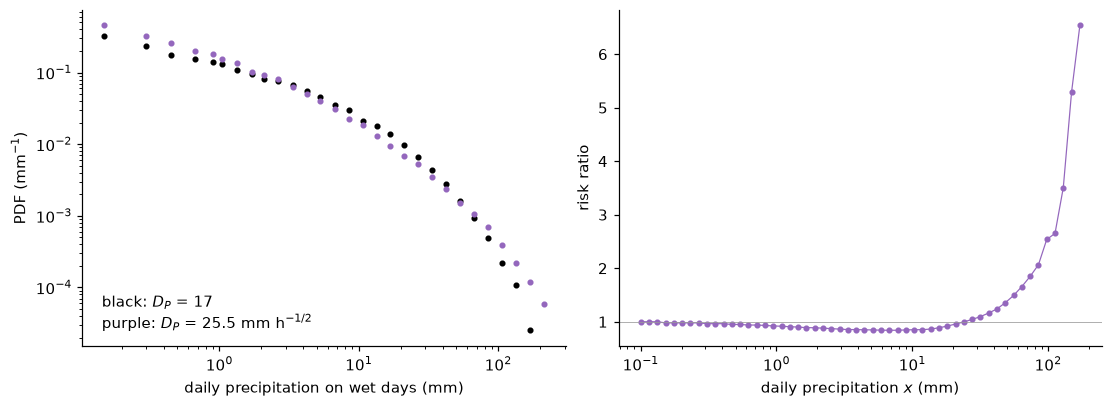

In [18]:
D_P_FACTOR = 1.5
LARGER_DP = dict(MN19_FIG2, D_P=D_P_FACTOR * MN19_FIG2["D_P"])
expt = run(simulate_fast, LARGER_DP, n_days=N_DAYS, dt_seconds=60.0, seed=4)
overview(expt)
print()
spell_table(expt)
print()
P_expt, w_expt = daily_table(expt)
print()
compare(one_min, expt, P_1min, P_expt)
print(f"\ntheory: s_L ratio = D_P_FACTOR^2 = {D_P_FACTOR**2:.2f}")

print(f"\n{'P(daily > x | wet day)':>24s}{'D_P = 17':>18s}{'D_P = 25.5':>18s}{'ratio':>8s}")
for x in [20, 50, 100, 150]:
    n_c, n_e = (P_1min > x).sum(), (P_expt > x).sum()
    p_c, p_e = n_c / P_1min.size, n_e / P_expt.size
    print(f"{'x = ' + str(x) + ' mm':>24s}{p_c:>10.4f} ({n_c:>4d}){p_e:>10.4f} ({n_e:>4d})"
          f"{p_e / p_c:>8.2f}")
print("(numbers of days in parentheses)")

fig, (ax_p, ax_r) = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for res, P, color in [(one_min, P_1min, "k"), (expt, P_expt, "tab:purple")]:
    x, pdf = log_binned_pdf(P, res["rain_step"])
    ax_p.loglog(x, pdf, "o", ms=3, color=color)
ax_p.text(0.04, 0.05, f"black: $D_P$ = {MN19_FIG2['D_P']:g}\npurple: $D_P$ = {LARGER_DP['D_P']:g} "
          "mm h$^{-1/2}$", transform=ax_p.transAxes)
ax_p.set(xlabel="daily precipitation on wet days (mm)", ylabel="PDF (mm$^{-1}$)")
# Risk ratio wherever both integrations have at least 10 wet days above x
xs = np.logspace(-1, 2.6, 60)
n_ctrl = np.array([(P_1min > x).sum() for x in xs])
n_expt = np.array([(P_expt > x).sum() for x in xs])
ok = (n_ctrl >= 10) & (n_expt >= 10)
xs, ratio = xs[ok], (n_expt[ok] / P_expt.size) / (n_ctrl[ok] / P_1min.size)
i_min = np.argmin(ratio)
x_cross = xs[i_min:][ratio[i_min:] > 1][0]
print(f"\nrisk ratio: minimum {ratio[i_min]:.2f} at x = {xs[i_min]:.0f} mm; "
      f"above 1 from x = {x_cross:.0f} mm")
ax_r.semilogx(xs, ratio, "o-", ms=3, lw=0.8, color="tab:purple")
ax_r.axhline(1, color="0.6", lw=0.5)
ax_r.set(xlabel="daily precipitation $x$ (mm)", ylabel="risk ratio")
plt.show()

The accumulation cutoff $s_L$ rises by a factor of 2.21, against the predicted 2.25. The method-of-moments daily cutoff $\hat P_L$ rises by less, a factor of 1.69, and $\hat\tau_P$ rises from 0.57 to 0.73. Eq. (17) predicts a factor of 2.02 for $\hat P_L$, less than 2.25 because its first term, $(\sigma_w^2/\bar w)\,\bar s$, changes little (from 6.18 to 6.42 mm) while $s_L/2$ grows. The integrations fall further below eq. (17) at the larger $D_P$: the method-of-moments $\hat P_L$ is 29.5 mm against eq. (17)'s 38.0 mm at $D_P$ = 17 mm h$^{-1/2}$, and 49.8 mm against 76.8 mm at 25.5 mm h$^{-1/2}$. The wet-spell cutoff $t_L$ is 15.6 h at the larger $D_P$, so a day is no longer much longer than $t_L$. MN19 Fig. 4a shows the integrations falling further below eq. (17) as $s_L$ increases, and their section 5b4 attributes this to $t_L$ growing with $s_L$.

The risk ratio falls below 1 for moderate daily totals, to 0.84 at 7 mm, and exceeds 1 from 28 mm upward, reaching 2.52 at 100 mm and 5.15 at 150 mm. MN19 describe the same pattern for their Fig. 8 case in which only $D_P$ increases: a lower probability of moderate daily precipitation, and a risk ratio growing exponentially at larger values.

## Possible extensions

- The dry regime: vary $\bar C$, as in MN19 Figs. 4b,d and 5 (right column), which show its effect on $\hat\tau_P$, $\hat P_L$ and the number of events per day.
- Ramp precipitation, MN19 eq. (8): $R(q) = \alpha (q - q_{np})$, with $\alpha$ = 0.35 h$^{-1}$ and $D_P$ = 12 mm h$^{-1/2}$ for the ramp model's distributions in their Fig. 2c. In `simulate` this changes the wet-regime drift and the precipitation added each step.
- Other averaging intervals (MN19 section 6): sum `daily` over consecutive days, or record subdaily totals in `simulate`.